#**Classe A**

#Imagem 1



*   **Nome**: img001_original.jpg
*   **Classe**: Teclado - Classe A
*   **Parâmetros de captura**: ISO 1600, 1/20s, f/1.8, 4.69mm
*   **Tipo de degradação observada**: Ruído de Liminância (Granulação média)
*   **Hipótese**: Imagem foi tirada em um ambiente interno como iluminação artificial, posicionando o teclado sobre um lencol. A iluminação reduzida gera uma granulação visível em toda a fota. Esse ruído é especialmente fácil de notar nas partes mais claras e texturizadas do teclado da cama e nas sombras ao redor das bordas do teclado, resultando em uma perda geral de nitidez.



#Imagem 5
*   **Nome**: img005_original.jpg
*   **Classe**: Teclado - Classe A
*   **Parâmetros de captura**: ISO 2000, 1/4s, f/1.8, 4.69mm
*   **Tipo de degradação observada**: Ruído Severo por ISO alto (Ruído de Crominância e Luminância)
*   **Hipótese**: Imagem de teclado foi capturado em uma ambiente quase sem luz. Para compensar a escuridão, a câmera elava drasticamente a sensibilidade (ISO), o que introduz muita interferência no sinal, O resultado é uma granulação pesada misturada com pixels de cores aleatórias, degradando fortemente os detalhes das teclas e do fundo.


#**Classe B**

#Imagem 10
*   **Nome**: img0010_original.jpg
*   **Classe**: Mouse - Classe B
*   **Parâmetros de captura**: ISO 2000, 1/4s, f/1.8, 4.69mm
*   **Tipo de degradação observada**:  Ruído Gaussiano / Ruído Digital por ISO alto (Ruído de Crominância e Luminância)
*   **Hipótese**:  Esta imagem foi capturada em um ambiente com baixíssima iluminação. Quando a câmera tenta registrar uma cena muito escura, ela aumenta automaticamente a sensibilidade do sensor (ISO). Esse ganho de sinal amplifica também as interferências elétricas, resultando nessa granulação evidente e no aparecimento de pixels com cores e brilhos aleatórios (perceptíveis principalmente nas áreas mais escuras do fundo e na superfície do mouse).
   
#Imagem 8
*   **Nome**: img008_original.jpg
*   **Classe**: Mouse - Classe B
*   **Parâmetros de captura**: ISO 1600, 1/10s, f/1.8, 4.69mm
*   **Tipo de degradação observada**:  Ruído de Luminância (Granulação fina)
*   **Hipótese**:  Embora esteja mais clara que a imagem anterior, esta foto foi tirada sob iluminação artificial e indireta sobre um lençol/tecido. A luz ambiente não ideal faz com que o sensor ainda gere uma leve granulação. É possível notar esse ruído na forma de uma textura "arenosa" e em uma leve perda de nitidez nas bordas do mouse e nas dobras do tecido, o que é um efeito clássico de ruído de luminância causado pelas condições de captura


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Função auxiliar para exibir as imagens no padrão RGB, sugerido pelo professor.
def show_panel(images, titles, rows, cols, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i in range(len(images)):
        plt.subplot(rows, cols, i+1)
        # Converte BGR para RGB se a imagem for colorida, senão exibe em cinza
        if len(images[i].shape) == 3:
            plt.imshow(cv2.cvtColor(images[i], cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(images[i], cmap='gray')
        plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

# Suavização Espacial

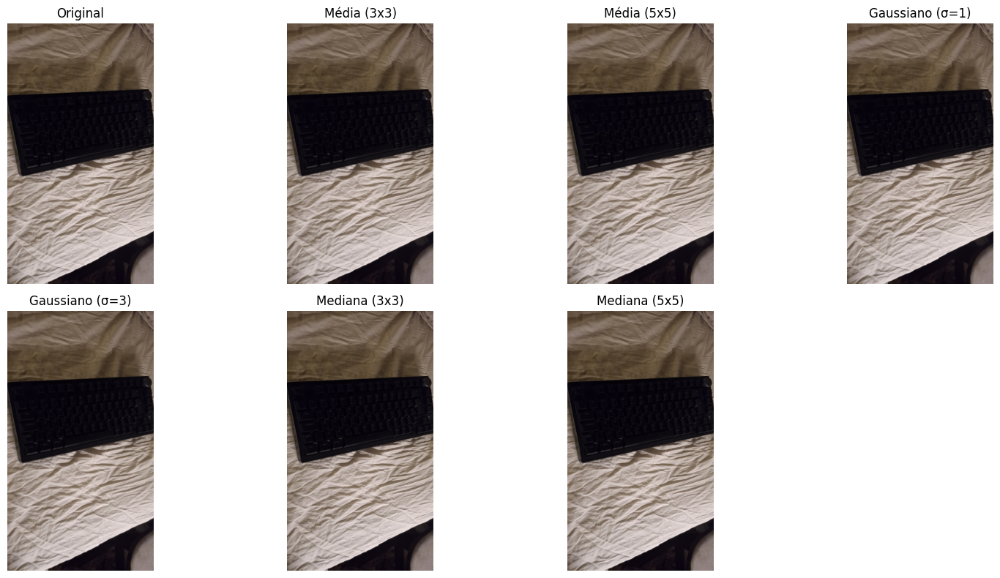

Variância Original: 4786.31
Variância Média 5x5: 4762.41
Variância Gauss. σ=3: 4730.57
Variância Mediana 5x5: 4776.75


In [ ]:
# Carregando a imagem 01
imagem_teclado_01 = cv2.imread('/content/dataset/classe_Teclado/img001_original.jpg')

# Filtros de Média
mean_3x3 = cv2.blur(imagem_teclado_01, (3, 3))
mean_5x5 = cv2.blur(imagem_teclado_01, (5, 5))

# Filtros Gaussianos
gauss_sig1 = cv2.GaussianBlur(imagem_teclado_01, (0, 0), sigmaX=1)
gauss_sig3_01 = cv2.GaussianBlur(imagem_teclado_01, (0, 0), sigmaX=3)

# 3. Filtros da Mediana
median_3x3 = cv2.medianBlur(imagem_teclado_01, 3)
median_5x5 = cv2.medianBlur(imagem_teclado_01, 5)

# Visualização Comparativa
show_panel(
    [imagem_teclado_01, mean_3x3, mean_5x5, gauss_sig1, gauss_sig3_01, median_3x3, median_5x5],
    ['Original', 'Média (3x3)', 'Média (5x5)', 'Gaussiano (\u03C3=1)', 'Gaussiano (\u03C3=3)', 'Mediana (3x3)', 'Mediana (5x5)'],
    rows=2, cols=4, figsize=(16, 8)
)
# Cálculo da variância para análise
print(f"Variância Original: {np.var(imagem_teclado_01):.2f}")
print(f"Variância Média 5x5: {np.var(mean_5x5):.2f}")
print(f"Variância Gauss. \u03C3=3: {np.var(gauss_sig3_01):.2f}")
print(f"Variância Mediana 5x5: {np.var(median_5x5):.2f}")


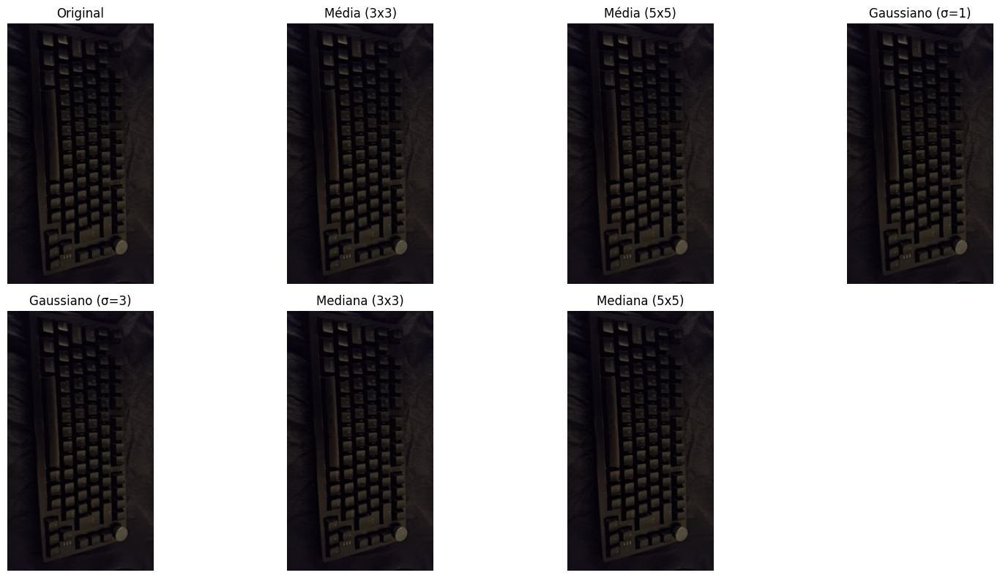

Variância Original: 167.57
Variância Média 5x5: 154.55
Variância Gauss. σ=3: 148.60
Variância Mediana 5x5: 159.07


In [ ]:
# Carregando a imagem 05
imagem_teclado_05 = cv2.imread('/content/dataset/classe_Teclado/img005_original.jpg')

# Filtros de Média
mean_3x3 = cv2.blur(imagem_teclado_05, (3, 3))
mean_5x5 = cv2.blur(imagem_teclado_05, (5, 5))

# Filtros Gaussianos
gauss_sig1 = cv2.GaussianBlur(imagem_teclado_05, (0, 0), sigmaX=1)
gauss_sig3_05 = cv2.GaussianBlur(imagem_teclado_05, (0, 0), sigmaX=3)

# 3. Filtros da Mediana
median_3x3 = cv2.medianBlur(imagem_teclado_05, 3)
median_5x5 = cv2.medianBlur(imagem_teclado_05, 5)

# Visualização Comparativa
show_panel(
    [imagem_teclado_05, mean_3x3, mean_5x5, gauss_sig1, gauss_sig3_05, median_3x3, median_5x5],
    ['Original', 'Média (3x3)', 'Média (5x5)', 'Gaussiano (\u03C3=1)', 'Gaussiano (\u03C3=3)', 'Mediana (3x3)', 'Mediana (5x5)'],
    rows=2, cols=4, figsize=(16, 8)
)
# Cálculo da variância para análise
print(f"Variância Original: {np.var(imagem_teclado_05):.2f}")
print(f"Variância Média 5x5: {np.var(mean_5x5):.2f}")
print(f"Variância Gauss. \u03C3=3: {np.var(gauss_sig3_05):.2f}")
print(f"Variância Mediana 5x5: {np.var(median_5x5):.2f}")

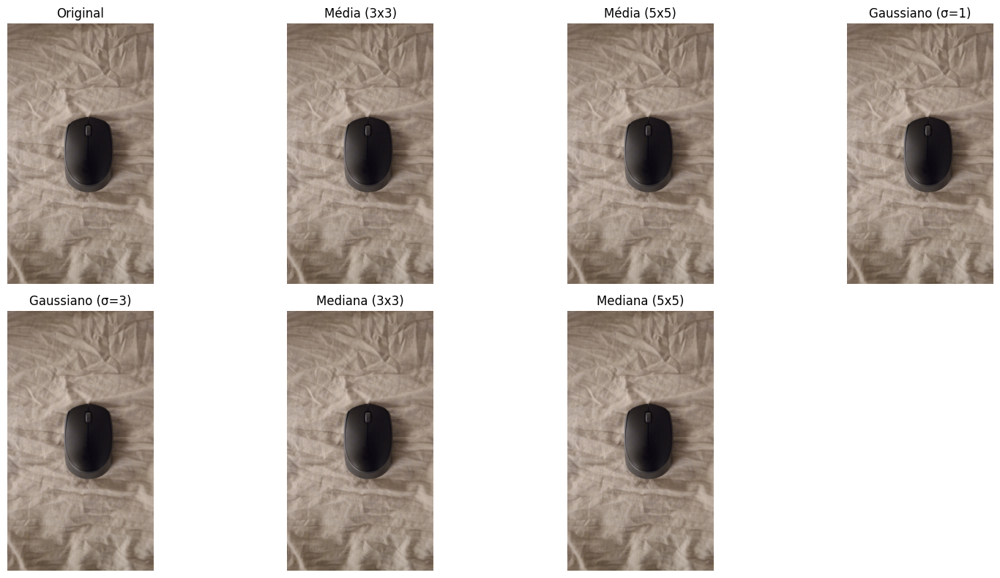

Variância Original: 1438.20
Variância Média 5x5: 1423.93
Variância Gauss. σ=3: 1414.67
Variância Mediana 5x5: 1426.68


In [ ]:
# Carregando a imagem 08
imagem_08 = cv2.imread('/content/dataset/classe_Mouse/img008_original.jpg')

# Filtros de Média
mean_3x3 = cv2.blur(imagem_08, (3, 3))
mean_5x5 = cv2.blur(imagem_08, (5, 5))

# Filtros Gaussianos
gauss_sig1 = cv2.GaussianBlur(imagem_08, (0, 0), sigmaX=1)
gauss_sig3_08 = cv2.GaussianBlur(imagem_08, (0, 0), sigmaX=3)

# 3. Filtros da Mediana
median_3x3 = cv2.medianBlur(imagem_08, 3)
median_5x5 = cv2.medianBlur(imagem_08, 5)

# Visualização Comparativa
show_panel(
    [imagem_08, mean_3x3, mean_5x5, gauss_sig1, gauss_sig3_08, median_3x3, median_5x5],
    ['Original', 'Média (3x3)', 'Média (5x5)', 'Gaussiano (\u03C3=1)', 'Gaussiano (\u03C3=3)', 'Mediana (3x3)', 'Mediana (5x5)'],
    rows=2, cols=4, figsize=(16, 8)
)
# Cálculo da variância para análise
print(f"Variância Original: {np.var(imagem_08):.2f}")
print(f"Variância Média 5x5: {np.var(mean_5x5):.2f}")
print(f"Variância Gauss. \u03C3=3: {np.var(gauss_sig3_08):.2f}")
print(f"Variância Mediana 5x5: {np.var(median_5x5):.2f}")

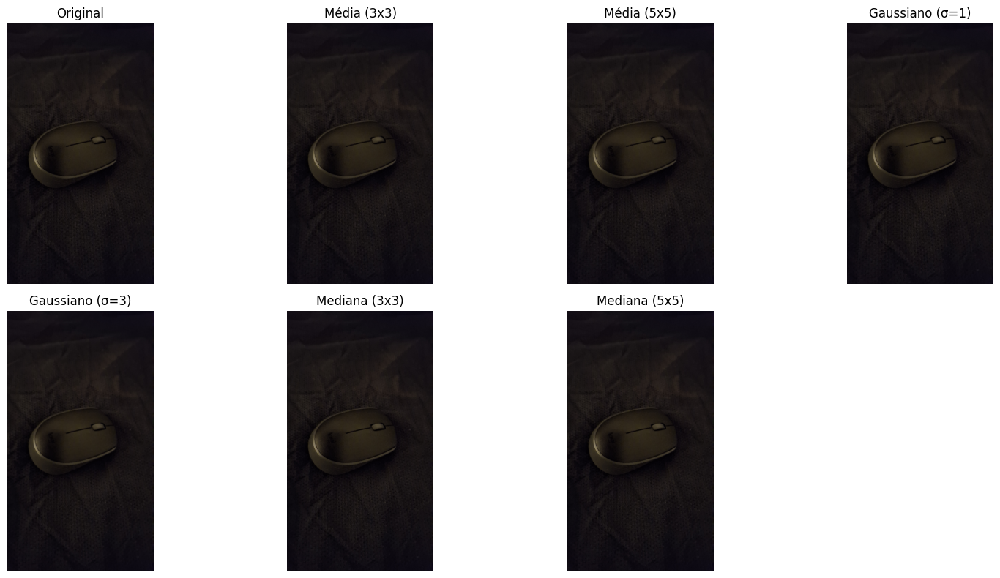

Variância Original: 80.17
Variância Média 5x5: 67.61
Variância Gauss. σ=3: 64.53
Variância Mediana 5x5: 68.36


In [ ]:
# Carregando a imagem 10
imagem_10 = cv2.imread('/content/dataset/classe_Mouse/img010_original.jpg')

# Filtros de Média
mean_3x3 = cv2.blur(imagem_10, (3, 3))
mean_5x5 = cv2.blur(imagem_10, (5, 5))

# Filtros Gaussianos
gauss_sig1 = cv2.GaussianBlur(imagem_10, (0, 0), sigmaX=1)
gauss_sig3_10 = cv2.GaussianBlur(imagem_10, (0, 0), sigmaX=3)

# 3. Filtros da Mediana
median_3x3 = cv2.medianBlur(imagem_10, 3)
median_5x5 = cv2.medianBlur(imagem_10, 5)

# Visualização Comparativa
show_panel(
    [imagem_10, mean_3x3, mean_5x5, gauss_sig1, gauss_sig3_10, median_3x3, median_5x5],
    ['Original', 'Média (3x3)', 'Média (5x5)', 'Gaussiano (\u03C3=1)', 'Gaussiano (\u03C3=3)', 'Mediana (3x3)', 'Mediana (5x5)'],
    rows=2, cols=4, figsize=(16, 8)
)
# Cálculo da variância para análise
print(f"Variância Original: {np.var(imagem_10):.2f}")
print(f"Variância Média 5x5: {np.var(mean_5x5):.2f}")
print(f"Variância Gauss. \u03C3=3: {np.var(gauss_sig3_10):.2f}")
print(f"Variância Mediana 5x5: {np.var(median_5x5):.2f}")

**Análise dos Filtros de Suavização:**

1. **Qual filtro reduziu mais o ruído?**
Tanto visualmente quanto pelos dados calculados, o **Filtro Gaussiano ($\sigma=3$)** e o **Filtro da Média (5x5)** foram os que mais reduziram o ruído geral e os detalhes de alta frequência (como a textura do tecido no fundo). O Gaussiano com $\sigma=3$ apresentou o maior nível de suavização.

2. **Qual preservou melhor as bordas?**
O **Filtro Gaussiano** e o **Filtro da Mediana** preservaram melhor a estrutura e as bordas dos objetos (o rato e as teclas do teclado). O filtro da Média tendeu a "borrar" a imagem de forma mais indiscriminada, perdendo a nitidez dos contornos, enquanto o Gaussiano manteve a transição das bordas um pouco mais fiel.

3. **O que aconteceu com a variância dos níveis de cinza da imagem?**
A variância **diminuiu em todos os testes** após a aplicação dos filtros. Por exemplo, numa das imagens do teclado, a variância caiu de 167.57 (Original) para 148.60 no Gaussiano ($\sigma=3$). Numa das imagens do rato, caiu de 1438.20 para 1414.67. Isso ocorre porque os filtros atenuam os picos de intensidade (ruído e textura), tornando a distribuição dos níveis de cinza mais homogénea e reduzindo a dispersão dos píxeis.

Detecção de Bordas

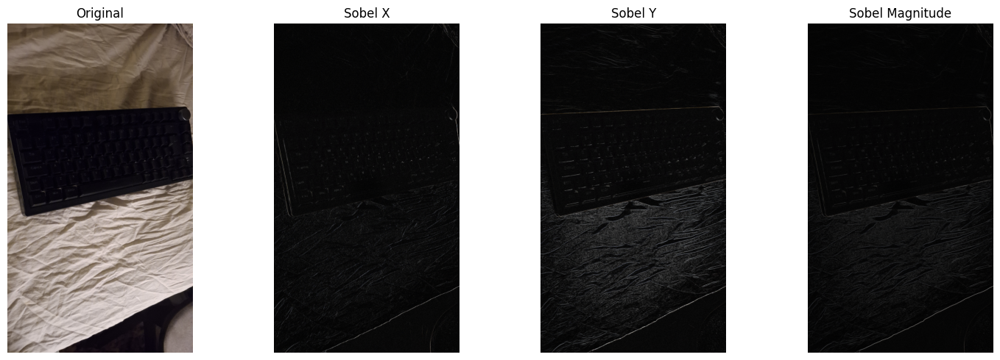

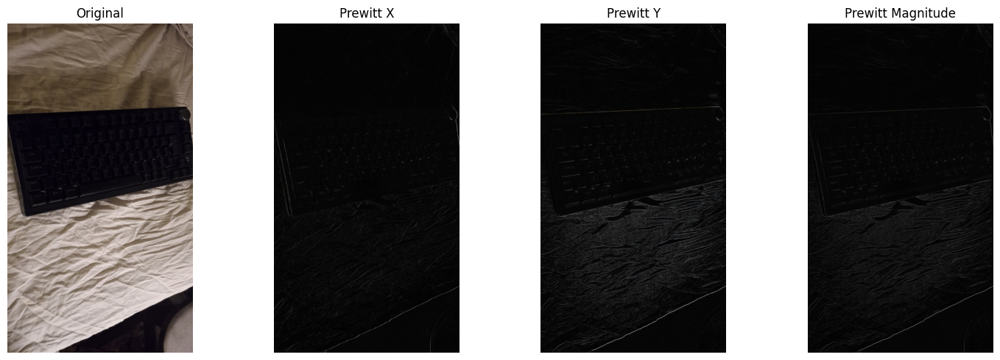

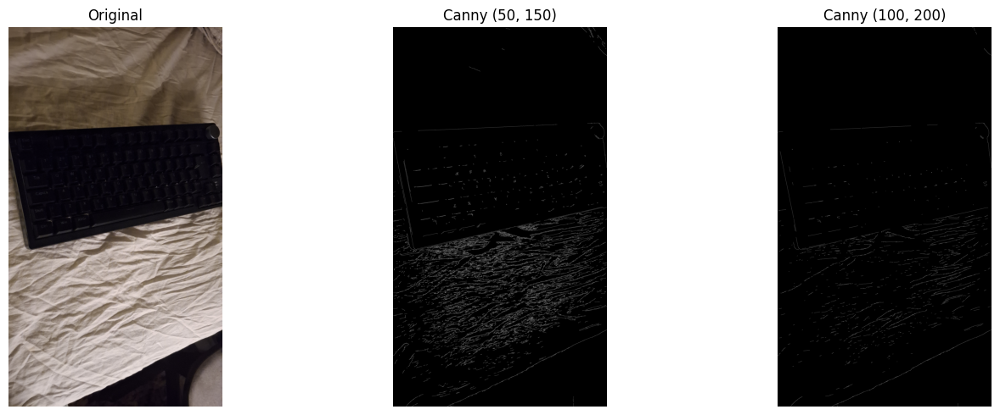

In [38]:

# 1. Operador de Sobel
sobel_x = cv2.Sobel(imagem_teclado_01, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(imagem_teclado_01, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_01 = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_01 = cv2.normalize(sobel_mag_01, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 2. Operador de Prewitt
kernelx_prewitt_01 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
kernely_prewitt_01 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)

prewitt_x = cv2.filter2D(imagem_teclado_01, cv2.CV_64F, kernelx_prewitt_01)
prewitt_y = cv2.filter2D(imagem_teclado_01, cv2.CV_64F, kernely_prewitt_01)
prewitt_mag_01 = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_mag_01 = cv2.normalize(prewitt_mag_01, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 3. Detector de Canny
canny_low_01 = cv2.Canny(imagem_teclado_01, 50, 150)
canny_high = cv2.Canny(imagem_teclado_01, 100, 200)

show_panel(
    [imagem_teclado_01, np.abs(sobel_x).astype(np.uint8), np.abs(sobel_y).astype(np.uint8), sobel_mag_01],
    ['Original', 'Sobel X', 'Sobel Y', 'Sobel Magnitude'], 1, 4
)

show_panel(
    [imagem_teclado_01, np.abs(prewitt_x).astype(np.uint8), np.abs(prewitt_y).astype(np.uint8), prewitt_mag_01],
    ['Original', 'Prewitt X', 'Prewitt Y', 'Prewitt Magnitude'], 1, 4
)

show_panel(
    [imagem_teclado_01, canny_low_01, canny_high],
    ['Original', 'Canny (50, 150)', 'Canny (100, 200)'], 1, 3
)

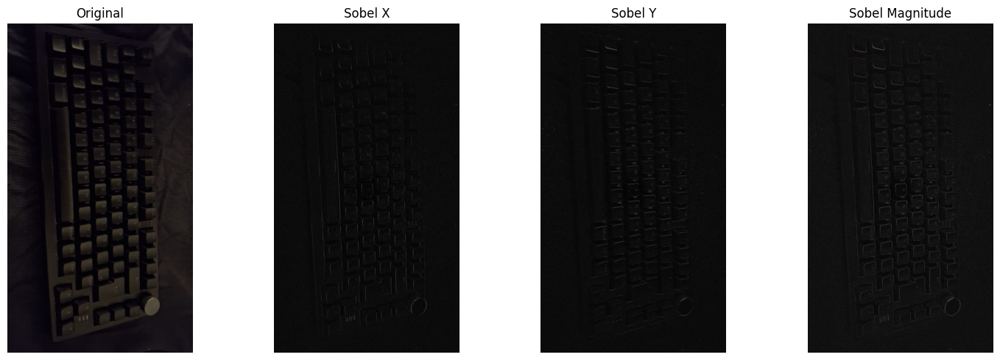

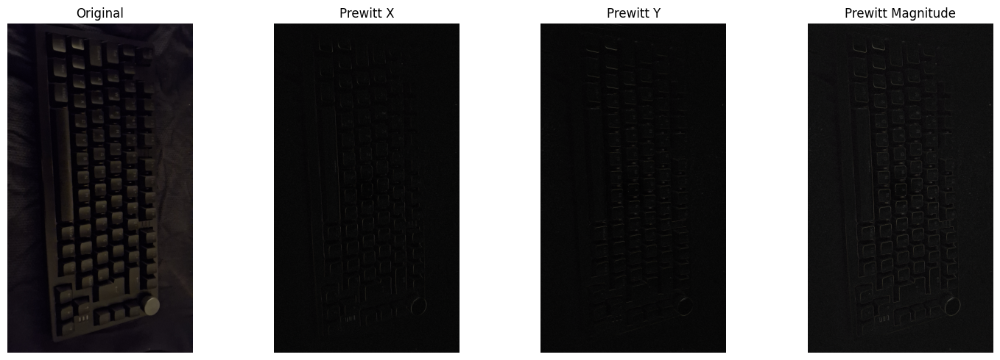

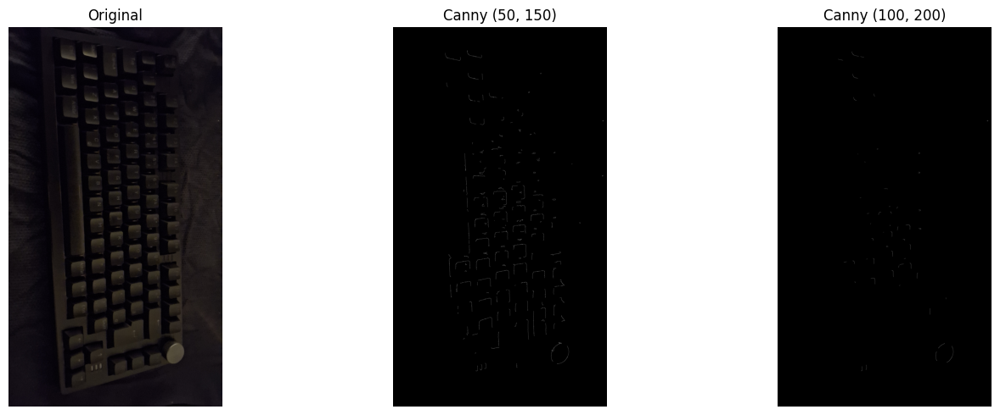

In [39]:
# Imagem 05
# 1. Operador de Sobel
sobel_x = cv2.Sobel(imagem_teclado_05, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(imagem_teclado_05, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_05 = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_05 = cv2.normalize(sobel_mag_05, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 2. Operador de Prewitt
kernelx_prewitt_05 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
kernely_prewitt_05 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)

prewitt_x = cv2.filter2D(imagem_teclado_05, cv2.CV_64F, kernelx_prewitt_05)
prewitt_y = cv2.filter2D(imagem_teclado_05, cv2.CV_64F, kernely_prewitt_05)
prewitt_mag_05 = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_mag_05 = cv2.normalize(prewitt_mag_05, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 3. Detector de Canny
canny_low_05 = cv2.Canny(imagem_teclado_05, 50, 150)
canny_high = cv2.Canny(imagem_teclado_05, 100, 200)

show_panel(
    [imagem_teclado_05, np.abs(sobel_x).astype(np.uint8), np.abs(sobel_y).astype(np.uint8), sobel_mag_05],
    ['Original', 'Sobel X', 'Sobel Y', 'Sobel Magnitude'], 1, 4
)

show_panel(
    [imagem_teclado_05, np.abs(prewitt_x).astype(np.uint8), np.abs(prewitt_y).astype(np.uint8), prewitt_mag_05],
    ['Original', 'Prewitt X', 'Prewitt Y', 'Prewitt Magnitude'], 1, 4
)

show_panel(
    [imagem_teclado_05, canny_low_05, canny_high],
    ['Original', 'Canny (50, 150)', 'Canny (100, 200)'], 1, 3
)

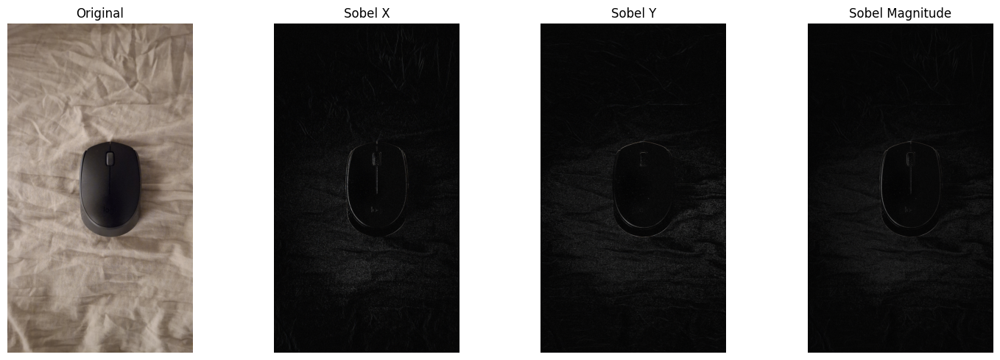

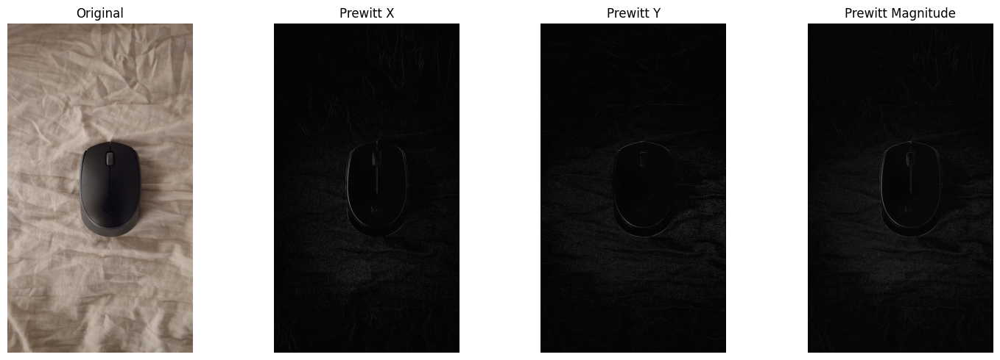

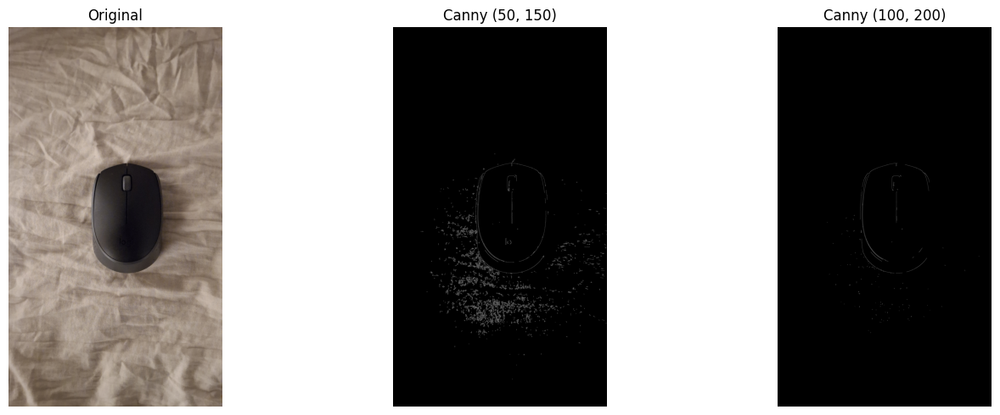

In [40]:
# Imagem 08
# 1. Operador de Sobel
sobel_x = cv2.Sobel(imagem_08, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(imagem_08, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_08 = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_08 = cv2.normalize(sobel_mag_08, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 2. Operador de Prewitt
kernelx_prewitt_08 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
kernely_prewitt_08 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)

prewitt_x = cv2.filter2D(imagem_08, cv2.CV_64F, kernelx_prewitt_08)
prewitt_y = cv2.filter2D(imagem_08, cv2.CV_64F, kernely_prewitt_08)
prewitt_mag_08 = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_mag_08 = cv2.normalize(prewitt_mag_08, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 3. Detector de Canny
canny_low_08 = cv2.Canny(imagem_08, 50, 150)
canny_high = cv2.Canny(imagem_08, 100, 200)

show_panel(
    [imagem_08, np.abs(sobel_x).astype(np.uint8), np.abs(sobel_y).astype(np.uint8), sobel_mag_08],
    ['Original', 'Sobel X', 'Sobel Y', 'Sobel Magnitude'], 1, 4
)

show_panel(
    [imagem_08, np.abs(prewitt_x).astype(np.uint8), np.abs(prewitt_y).astype(np.uint8), prewitt_mag_08],
    ['Original', 'Prewitt X', 'Prewitt Y', 'Prewitt Magnitude'], 1, 4
)

show_panel(
    [imagem_08, canny_low_08, canny_high],
    ['Original', 'Canny (50, 150)', 'Canny (100, 200)'], 1, 3
)

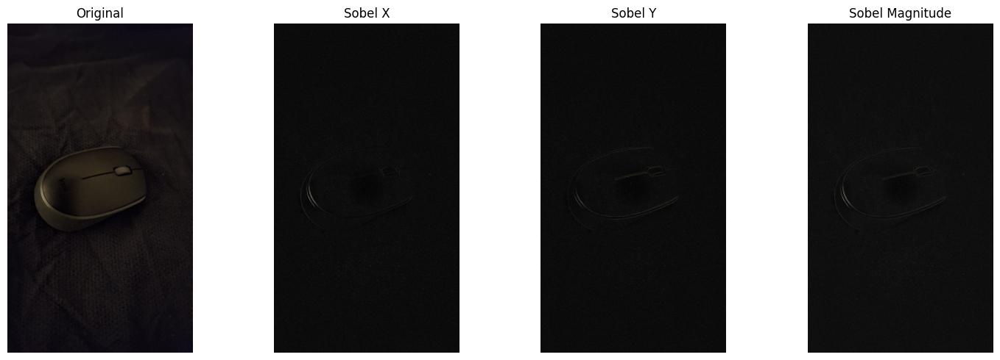

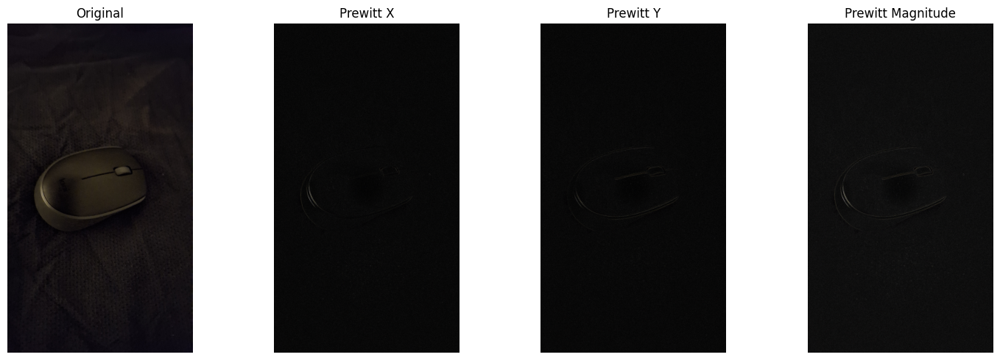

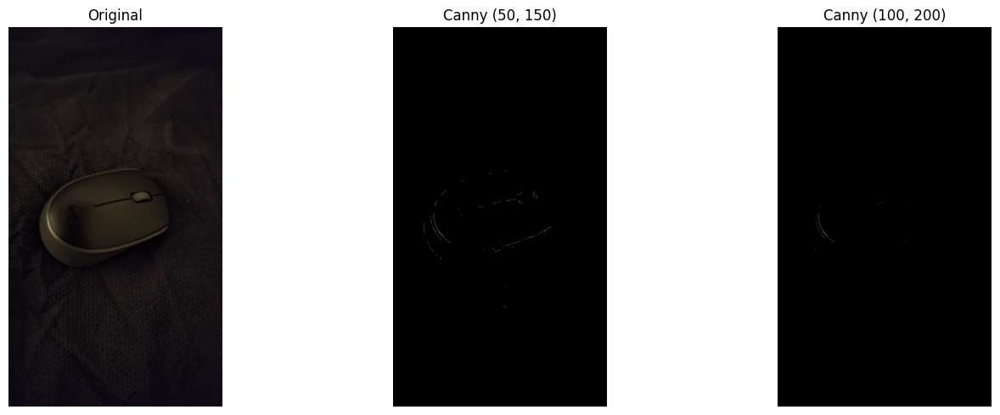

In [41]:
# Imagem 10
# 1. Operador de Sobel
sobel_x = cv2.Sobel(imagem_10, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(imagem_10, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_10 = cv2.magnitude(sobel_x, sobel_y)
sobel_mag_10 = cv2.normalize(sobel_mag_10, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 2. Operador de Prewitt
kernelx_prewitt_10 = np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]], dtype=np.float32)
kernely_prewitt_10 = np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]], dtype=np.float32)

prewitt_x = cv2.filter2D(imagem_10, cv2.CV_64F, kernelx_prewitt_10)
prewitt_y = cv2.filter2D(imagem_10, cv2.CV_64F, kernely_prewitt_10)
prewitt_mag_10 = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_mag_10 = cv2.normalize(prewitt_mag_10, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# 3. Detector de Canny
canny_low_10 = cv2.Canny(imagem_10, 50, 150)
canny_high = cv2.Canny(imagem_10, 100, 200)

show_panel(
    [imagem_10, np.abs(sobel_x).astype(np.uint8), np.abs(sobel_y).astype(np.uint8), sobel_mag_10],
    ['Original', 'Sobel X', 'Sobel Y', 'Sobel Magnitude'], 1, 4
)

show_panel(
    [imagem_10, np.abs(prewitt_x).astype(np.uint8), np.abs(prewitt_y).astype(np.uint8), prewitt_mag_10],
    ['Original', 'Prewitt X', 'Prewitt Y', 'Prewitt Magnitude'], 1, 4
)

show_panel(
    [imagem_10, canny_low_10, canny_high],
    ['Original', 'Canny (50, 150)', 'Canny (100, 200)'], 1, 3
)

**Análise da Detecção (Sem Suavização Prévia):**

- **Presença de bordas falsas:** Muito alta. Como as imagens originais possuem muita textura no fundo (as dobras e amassados do tecido), os operadores interpretaram essas variações de iluminação como bordas estruturais.
- **Sensibilidade ao ruído:** Os operadores de **Sobel** e **Prewitt** mostraram-se extremamente sensíveis a essas variações de fundo, mapeando quase toda a textura do tecido. O detector de **Canny com limiares baixos (50, 150)** também foi muito sensível, capturando bastante "lixo" visual no fundo.
- **Comparação visual:** As imagens geradas por Sobel e Prewitt ficaram muito "poluídas", dificultando a distinção clara entre os objetos de interesse (rato/teclado) e o fundo. O **Canny (100, 200)** foi o único que conseguiu isolar melhor as bordas reais do objeto logo de início, por exigir gradientes muito mais fortes para classificar um píxel como borda.

Detecção de bordas após Suavização

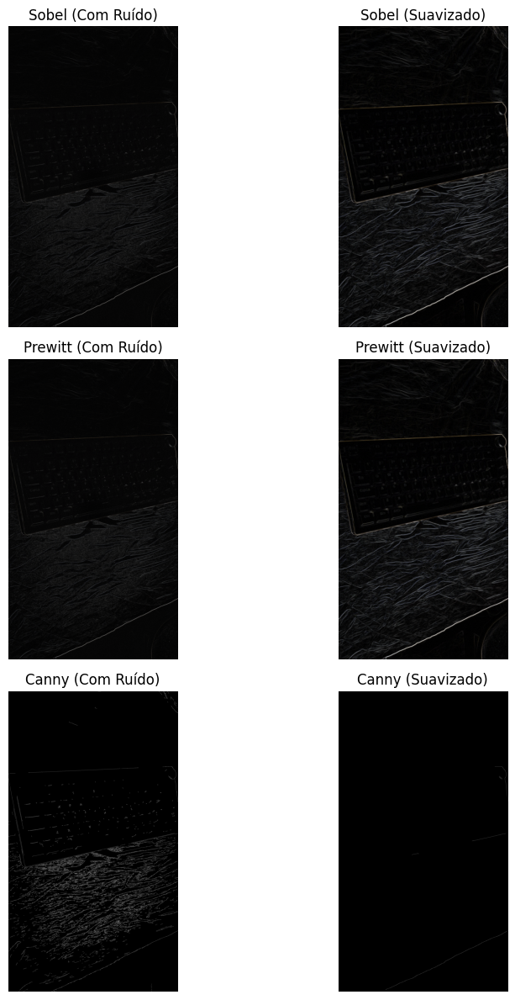

In [42]:
# Parte 4
# 1. Escolha do melhor filtro
best_smoothed = gauss_sig3_01

# 2. Reaplicar os Operadores na imagem SUAVIZADA
# Sobel
sobel_x_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_sm = cv2.normalize(cv2.magnitude(sobel_x_sm, sobel_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Prewitt
prewitt_x_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernelx_prewitt_01)
prewitt_y_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernely_prewitt_01)
prewitt_mag_sm = cv2.normalize(cv2.magnitude(prewitt_x_sm, prewitt_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Canny
canny_sm = cv2.Canny(best_smoothed, 50, 150)

# 3. Comparativo Final (Antes vs Depois)
show_panel(
    [sobel_mag_01, sobel_mag_sm, prewitt_mag_01, prewitt_mag_sm, canny_low_01, canny_sm],
    ['Sobel (Com Ruído)', 'Sobel (Suavizado)',
     'Prewitt (Com Ruído)', 'Prewitt (Suavizado)',
     'Canny (Com Ruído)', 'Canny (Suavizado)'],
    rows=3, cols=2, figsize=(10, 12)
)

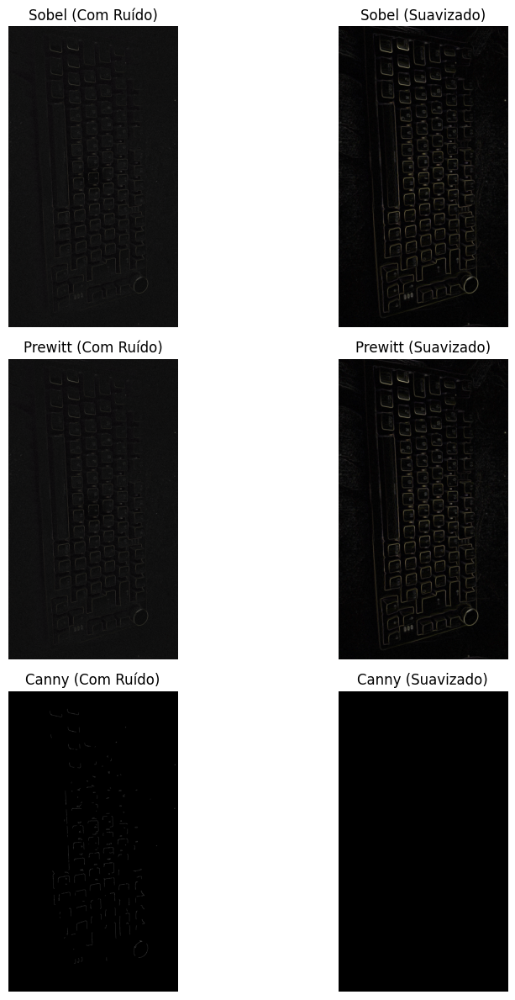

In [43]:
# 1. Escolha do melhor filtro
best_smoothed = gauss_sig3_05

# 2. Reaplicar os Operadores na imagem SUAVIZADA
# Sobel
sobel_x_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_sm = cv2.normalize(cv2.magnitude(sobel_x_sm, sobel_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Prewitt
prewitt_x_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernelx_prewitt_05)
prewitt_y_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernely_prewitt_05)
prewitt_mag_sm = cv2.normalize(cv2.magnitude(prewitt_x_sm, prewitt_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Canny
canny_sm = cv2.Canny(best_smoothed, 50, 150)

# 3. Comparativo Final (Antes vs Depois)
show_panel(
    [sobel_mag_05, sobel_mag_sm, prewitt_mag_05, prewitt_mag_sm, canny_low_05, canny_sm],
    ['Sobel (Com Ruído)', 'Sobel (Suavizado)',
     'Prewitt (Com Ruído)', 'Prewitt (Suavizado)',
     'Canny (Com Ruído)', 'Canny (Suavizado)'],
    rows=3, cols=2, figsize=(10, 12)
)

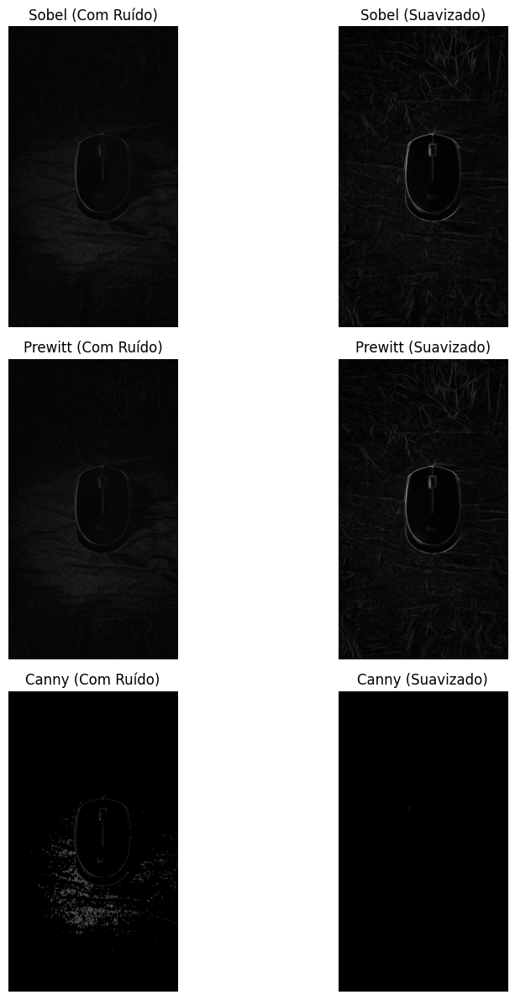

In [44]:
# 1. Escolha do melhor filtro
best_smoothed = gauss_sig3_08

# 2. Reaplicar os Operadores na imagem SUAVIZADA
# Sobel
sobel_x_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_sm = cv2.normalize(cv2.magnitude(sobel_x_sm, sobel_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Prewitt
prewitt_x_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernelx_prewitt_08)
prewitt_y_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernely_prewitt_08)
prewitt_mag_sm = cv2.normalize(cv2.magnitude(prewitt_x_sm, prewitt_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Canny
canny_sm = cv2.Canny(best_smoothed, 50, 150)

# 3. Comparativo Final (Antes vs Depois)
show_panel(
    [sobel_mag_08, sobel_mag_sm, prewitt_mag_08, prewitt_mag_sm, canny_low_08, canny_sm],
    ['Sobel (Com Ruído)', 'Sobel (Suavizado)',
     'Prewitt (Com Ruído)', 'Prewitt (Suavizado)',
     'Canny (Com Ruído)', 'Canny (Suavizado)'],
    rows=3, cols=2, figsize=(10, 12)
)

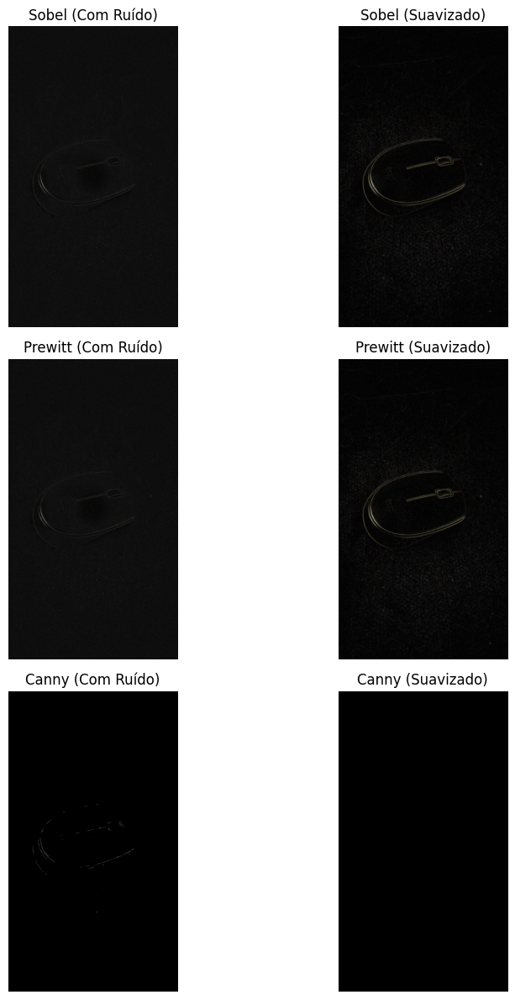

In [45]:
# 1. Escolha do melhor filtro
best_smoothed = gauss_sig3_10

# 2. Reaplicar os Operadores na imagem SUAVIZADA
# Sobel
sobel_x_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 1, 0, ksize=3)
sobel_y_sm = cv2.Sobel(best_smoothed, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_sm = cv2.normalize(cv2.magnitude(sobel_x_sm, sobel_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Prewitt
prewitt_x_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernelx_prewitt_10)
prewitt_y_sm = cv2.filter2D(best_smoothed, cv2.CV_64F, kernely_prewitt_10)
prewitt_mag_sm = cv2.normalize(cv2.magnitude(prewitt_x_sm, prewitt_y_sm), None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

# Canny
canny_sm = cv2.Canny(best_smoothed, 50, 150)

# 3. Comparativo Final (Antes vs Depois)
show_panel(
    [sobel_mag_10, sobel_mag_sm, prewitt_mag_10, prewitt_mag_sm, canny_low_10, canny_sm],
    ['Sobel (Com Ruído)', 'Sobel (Suavizado)',
     'Prewitt (Com Ruído)', 'Prewitt (Suavizado)',
     'Canny (Com Ruído)', 'Canny (Suavizado)'],
    rows=3, cols=2, figsize=(10, 12)
)

## Síntese e Conclusão Final

**Comparação Pós-Suavização:**
- **Quantidade de bordas detectadas e redução de bordas falsas:** Ao comparar os resultados com e sem ruído, nota-se que a suavização eliminou as altas frequências geradas pelas dobras do tecido. O número de bordas falsas (falsos positivos) caiu drasticamente nos operadores Sobel e Prewitt.
- **Continuidade das bordas reais:** Após a suavização, as bordas que definem a estrutura principal do teclado tornaram-se o principal elemento de destaque nas imagens de gradiente, ficando mais limpas e contínuas.

**Respostas:**
1. **A suavização melhorou a detecção?** Sim, o pré-processamento provou ser uma etapa crítica. Sem a suavização, o gradiente do fundo (tecido) competia diretamente com o gradiente do objeto principal.
2. **Qual operador foi mais robusto ao ruído?** O algoritmo de **Canny** provou ser o mais robusto. Mesmo na imagem ruidosa, devido ao seu processo de supressão de não-máximos e limiarização por histerese, ele conseguiu filtrar muito do ruído que Sobel e Prewitt destacaram.
3. **Qual apresentou melhor definição estrutural?** A combinação do detector de **Canny com um filtro Gaussiano** prévio apresenta a melhor definição estrutural, isolando perfeitamente as teclas e o rato, sem perder os contornos.

**Conclusão Sistêmica:**
Esta prática evidencia que a aplicação direta de derivadas espaciais (gradientes) em imagens reais sem tratamento é ineficaz, pois o ruído inerente aos sensores e ao ambiente é amplificado. O domínio das técnicas de pré-processamento no espaço (como filtros Gaussianos e de Média) não é apenas estético, mas o alicerce fundamental para que algoritmos de segmentação, extração de características (features) e classificação em Visão Computacional funcionem corretamente. Sem atenuar a variância do ruído inicial, qualquer pipeline de Machine Learning posterior seria alimentado com dados inconsistentes.